# Proyek Analisis Data: E-Commerce Public Dataset

**Nama:** Ariani Dwi Septi  
**Email:** arianidsepti01@gmail.com  
**ID Dicoding:** [ID Dicoding Anda]

## Deskripsi Proyek

Proyek ini bertujuan menganalisis data e-commerce publik untuk menjawab pertanyaan bisnis
terkait perilaku pelanggan dan performa penjualan, menggunakan teknik analisis data dengan Python.

## 1. Gathering Data

Pada tahap ini, seluruh dataset yang dibutuhkan dimuat ke dalam DataFrame menggunakan library pandas.
Dataset yang digunakan adalah **E-Commerce Public Dataset** yang terdiri dari beberapa file CSV.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

Matplotlib is building the font cache; this may take a moment.


### 1.1 Customers Dataset

Dataset ini berisi informasi pelanggan, termasuk `customer_id`, `customer_unique_id`,
`customer_zip_code_prefix`, `customer_city`, dan `customer_state`.

In [2]:
customers_df = pd.read_csv('data/customers_dataset.csv')
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### 1.2 Orders Dataset

Dataset ini berisi informasi pesanan, meliputi:
- `order_id`: ID unik pesanan.
- `customer_id`: ID pelanggan yang memesan.
- `order_status`: status pesanan (delivered, shipped, canceled, dll.).
- `order_purchase_timestamp`: waktu pesanan dibuat.
- `order_approved_at`: waktu pembayaran disetujui.
- `order_delivered_carrier_date`: waktu pesanan diserahkan ke kurir.
- `order_delivered_customer_date`: waktu pesanan diterima pelanggan.
- `order_estimated_delivery_date`: estimasi waktu pengiriman.

In [4]:
orders_df = pd.read_csv('data/orders_dataset.csv')
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


### 1.3 Order Items Dataset

Dataset ini berisi rincian item pada setiap pesanan, meliputi:
- `order_id`: ID pesanan.
- `order_item_id`: nomor urut item dalam pesanan.
- `product_id`: ID produk.
- `seller_id`: ID penjual.
- `shipping_limit_date`: batas waktu pengiriman.
- `price`: harga produk.
- `freight_value`: biaya pengiriman.

In [5]:
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


### 1.4 Products Dataset

Dataset ini berisi informasi produk, meliputi:
- `product_id`: ID unik produk.
- `product_category_name`: kategori produk (dalam bahasa Portugis).
- `product_name_lenght`, `product_description_lenght`: panjang nama & deskripsi.
- `product_photos_qty`: jumlah foto produk.
- `product_weight_g`, `product_length_cm`, `product_height_cm`, `product_width_cm`: dimensi & berat produk.

In [6]:
products_df = pd.read_csv('data/products_dataset.csv')
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


### 1.5 Order Payments Dataset

Dataset ini berisi informasi pembayaran tiap pesanan, meliputi:
- `order_id`: ID pesanan.
- `payment_sequential`: urutan pembayaran (jika satu pesanan dibayar dengan beberapa metode).
- `payment_type`: metode pembayaran (credit_card, boleto, voucher, debit_card, dll.).
- `payment_installments`: jumlah cicilan.
- `payment_value`: nilai pembayaran.

In [7]:
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')
order_payments_df.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


### 1.6 Order Reviews Dataset

Dataset ini berisi ulasan pelanggan terhadap pesanan, meliputi:
- `review_id`: ID ulasan.
- `order_id`: ID pesanan yang diulas.
- `review_score`: skor ulasan 1–5.
- `review_comment_title`, `review_comment_message`: judul & isi komentar.
- `review_creation_date`, `review_answer_timestamp`: tanggal ulasan dibuat & dijawab.

In [8]:
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
order_reviews_df.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


### 1.7 Sellers Dataset

Dataset ini berisi informasi penjual, meliputi:
- `seller_id`: ID unik penjual.
- `seller_zip_code_prefix`: kode pos penjual.
- `seller_city`: kota penjual.
- `seller_state`: negara bagian penjual.

In [9]:
sellers_df = pd.read_csv('data/sellers_dataset.csv')
sellers_df.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


### 1.8 Geolocation Dataset

Dataset ini berisi data koordinat geografis berdasarkan kode pos, meliputi:
- `geolocation_zip_code_prefix`: kode pos.
- `geolocation_lat`: garis lintang.
- `geolocation_lng`: garis bujur.
- `geolocation_city`: kota.
- `geolocation_state`: negara bagian.

Dataset ini nantinya berguna untuk analisis geospasial (salah satu saran rating tinggi).

In [10]:
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')
geolocation_df.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


### 1.9 Product Category Name Translation Dataset

Dataset ini berisi terjemahan nama kategori produk dari bahasa Portugis ke bahasa Inggris, meliputi:
- `product_category_name`: nama kategori (Portugis).
- `product_category_name_english`: nama kategori (Inggris).

Dataset ini akan digabungkan dengan dataset Products agar kategori mudah dibaca.

In [11]:
category_translation_df = pd.read_csv('data/product_category_name_translation.csv')
category_translation_df.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [12]:
datasets = {
    'customers': customers_df,
    'orders': orders_df,
    'order_items': order_items_df,
    'products': products_df,
    'order_payments': order_payments_df,
    'order_reviews': order_reviews_df,
    'sellers': sellers_df,
    'geolocation': geolocation_df,
    'category_translation': category_translation_df
}

for name, df in datasets.items():
    print(f"{name:25s} -> {df.shape[0]:>8,} baris, {df.shape[1]} kolom")

customers                 ->   99,441 baris, 5 kolom
orders                    ->   99,441 baris, 8 kolom
order_items               ->  112,650 baris, 7 kolom
products                  ->   32,951 baris, 9 kolom
order_payments            ->  103,886 baris, 5 kolom
order_reviews             ->   99,224 baris, 7 kolom
sellers                   ->    3,095 baris, 4 kolom
geolocation               -> 1,000,163 baris, 5 kolom
category_translation      ->       71 baris, 2 kolom


## 2. Assessing Data

Pada tahap ini, dilakukan penilaian kualitas data untuk mengidentifikasi permasalahan
yang terdapat pada dataset. Permasalahan yang ditemukan akan dijadikan dasar pada tahap
Cleaning Data.

Permasalahan yang akan diperiksa meliputi:
- Missing value
- Duplicate data
- Kesalahan tipe data
- Nilai tidak valid / tidak konsisten
- Outlier

In [13]:
for name, df in datasets.items():
    print(f"===== {name} =====")
    print(df.info())
    print(f"Jumlah missing value per kolom:\n{df.isna().sum()}\n")

===== customers =====
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB
None
Jumlah missing value per kolom:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

===== orders =====
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                  

In [14]:
for name, df in datasets.items():
    dup = df.duplicated().sum()
    print(f"{name:25s} -> {dup} baris duplikat")

customers                 -> 0 baris duplikat
orders                    -> 0 baris duplikat
order_items               -> 0 baris duplikat
products                  -> 0 baris duplikat
order_payments            -> 0 baris duplikat
order_reviews             -> 0 baris duplikat
sellers                   -> 0 baris duplikat
geolocation               -> 261831 baris duplikat
category_translation      -> 0 baris duplikat


In [15]:
for name in ['order_items', 'order_payments', 'products', 'order_reviews']:
    print(f"===== {name} =====")
    print(datasets[name].describe())
    print()

===== order_items =====
       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000

===== order_payments =====
       payment_sequential  payment_installments  payment_value
count       103886.000000         103886.000000  103886.000000
mean             1.092679              2.853349     154.100380
std              0.706584              2.687051     217.494064
min              1.000000              0.000000       0.000000
25%              1.000000              1.000000      56.790000
50%              1.000000              1.000000     100.000000
75%              1.000000              4.000000 

In [16]:
# Status pesanan yang tidak valid
print("Status pesanan unik:")
print(orders_df['order_status'].value_counts())
print()

# Skor ulasan di luar 1-5
print("Rentang review_score:", order_reviews_df['review_score'].min(), "-", order_reviews_df['review_score'].max())
print()

# Payment type unik
print("Payment type unik:")
print(order_payments_df['payment_type'].value_counts())
print()

# Harga <= 0 pada order_items
print("Jumlah order_items dengan price <= 0:", (order_items_df['price'] <= 0).sum())
print("Jumlah order_items dengan freight_value < 0:", (order_items_df['freight_value'] < 0).sum())
print()

# Produk tanpa kategori
print("Jumlah produk tanpa kategori:", products_df['product_category_name'].isna().sum())

Status pesanan unik:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rentang review_score: 1 - 5

Payment type unik:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Jumlah order_items dengan price <= 0: 0
Jumlah order_items dengan freight_value < 0: 0

Jumlah produk tanpa kategori: 610


In [17]:
# Cek apakah ada order_delivered_customer_date lebih awal dari order_purchase_timestamp
orders_df['order_purchase_timestamp'] = pd.to_datetime(orders_df['order_purchase_timestamp'], errors='coerce')
orders_df['order_delivered_customer_date'] = pd.to_datetime(orders_df['order_delivered_customer_date'], errors='coerce')

invalid_delivery = (orders_df['order_delivered_customer_date'] < orders_df['order_purchase_timestamp']).sum()
print("Jumlah pesanan dengan tanggal terima < tanggal beli:", invalid_delivery)

Jumlah pesanan dengan tanggal terima < tanggal beli: 0


### Ringkasan Permasalahan Data yang Ditemukan

Berdasarkan proses assessing data di atas, ditemukan beberapa permasalahan berikut:

**1. Missing Value**

- `orders_df`:
  - `order_approved_at`: 160 missing value
  - `order_delivered_carrier_date`: 1.783 missing value
  - `order_delivered_customer_date`: 2.965 missing value
  - Missing value ini wajar terjadi karena tidak semua pesanan disetujui, dikirim, atau diterima
    (misalnya pesanan berstatus `canceled` atau `unavailable`). Namun tetap perlu ditangani
    agar analisis berbasis tanggal tidak bias.

- `products_df`:
  - `product_category_name`, `product_name_lenght`, `product_description_lenght`,
    `product_photos_qty`: masing-masing 610 missing value.
  - `product_weight_g`, `product_length_cm`, `product_height_cm`, `product_width_cm`:
    masing-masing 2 missing value.

- `order_reviews_df`:
  - `review_comment_title`: 87.656 missing value
  - `review_comment_message`: 58.247 missing value
  - Missing value ini wajar karena pelanggan tidak selalu menulis judul/komentar ulasan.

**2. Kesalahan Tipe Data**

- Kolom tanggal pada `orders_df` masih bertipe `str` (object), padahal seharusnya `datetime`:
  `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`,
  `order_delivered_customer_date`, `order_estimated_delivery_date`.
- Kolom tanggal pada `order_items_df` (`shipping_limit_date`) masih bertipe `str`.
- Kolom tanggal pada `order_reviews_df` (`review_creation_date`, `review_answer_timestamp`)
  masih bertipe `str`.

**3. Duplicate Data**

- `geolocation_df` memiliki **261.831 baris duplikat** dari total 1.000.163 baris.
  Hal ini terjadi karena satu kode pos dapat memiliki beberapa titik koordinat.
- Dataset lain tidak memiliki baris duplikat.

**4. Nilai Tidak Valid / Tidak Konsisten**

- `order_payments_df`:
  - Terdapat `payment_value` minimum 0, yang menandakan pembayaran tidak valid.
  - Terdapat `payment_installments` minimum 0.
  - Terdapat 3 transaksi dengan `payment_type` = `not_defined`.
- `order_items_df`: tidak ditemukan `price <= 0` maupun `freight_value < 0`.
- `order_reviews_df`: `review_score` berada pada rentang valid 1–5, tidak ada nilai di luar rentang.
- `products_df`: terdapat **610 produk tanpa kategori** (`product_category_name` kosong).
- `orders_df`: tidak ditemukan pesanan dengan `order_delivered_customer_date` lebih awal
  dari `order_purchase_timestamp` (0 baris), sehingga konsistensi tanggal terjamin.

**5. Outlier**

- `order_items_df`:
  - `price` memiliki nilai maksimum 6.735, jauh di atas Q3 (134,9) — terdapat outlier
    pada transaksi bernilai tinggi.
  - `freight_value` maksimum 409,68, juga mengindikasikan outlier.
- `order_payments_df`: `payment_value` maksimum 13.664,08 — terdapat outlier.
- `products_df`: `product_weight_g` minimum 0 (tidak valid secara fisik) dan maksimum
  40.425 gram — terdapat outlier pada dimensi/berat produk.
- `order_reviews_df`: tidak ditemukan outlier karena `review_score` terbatas 1–5.

### Rencana Solusi (akan dilakukan pada tahap Cleaning Data)

Berdasarkan permasalahan yang ditemukan pada tahap Assessing Data, berikut rencana
penanganan yang akan dilakukan pada tahap Cleaning Data:

**1. Menangani Missing Value**

- `orders_df`:
  - Kolom `order_approved_at`, `order_delivered_carrier_date`, dan
    `order_delivered_customer_date` **tidak diisi (imputasi)**, melainkan dibiarkan kosong
    karena missing value di sini bermakna bahwa tahapan tersebut memang belum/tidak terjadi
    (misalnya pesanan berstatus `canceled` atau `unavailable`).
  - Untuk analisis yang membutuhkan tanggal pengiriman, baris dengan
    `order_delivered_customer_date` kosong akan **difilter** pada saat analisis, bukan dihapus
    permanen dari dataset utama.

- `products_df`:
  - `product_category_name` yang kosong (610 baris) akan diisi dengan kategori `"unknown"`.
  - Kolom `product_name_lenght`, `product_description_lenght`, dan `product_photos_qty`
    yang kosong akan diisi dengan nilai **median** kolom masing-masing.
  - Kolom dimensi (`product_weight_g`, `product_length_cm`, `product_height_cm`,
    `product_width_cm`) yang kosong (2 baris) akan diisi dengan nilai **median**.

- `order_reviews_df`:
  - Kolom `review_comment_title` dan `review_comment_message` **dibiarkan kosong**
    karena komentar ulasan bersifat opsional dan bukan bagian dari pertanyaan bisnis.

**2. Memperbaiki Tipe Data**

- Mengubah kolom tanggal pada `orders_df` menjadi `datetime`:
  `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`,
  `order_delivered_customer_date`, `order_estimated_delivery_date`.
- Mengubah `shipping_limit_date` pada `order_items_df` menjadi `datetime`.
- Mengubah `review_creation_date` dan `review_answer_timestamp` pada `order_reviews_df`
  menjadi `datetime`.
- Konversi dilakukan dengan `pd.to_datetime(..., errors='coerce')` agar nilai yang gagal
  dikonversi menjadi `NaT` dan tidak menyebabkan error.

**3. Menangani Duplicate Data**

- `geolocation_df` memiliki 261.831 baris duplikat. Duplikat akan dihapus dengan
  `drop_duplicates()`. Jika masih terdapat lebih dari satu koordinat untuk satu kode pos,
  akan diambil **satu koordinat representatif** (nilai rata-rata `geolocation_lat` dan
  `geolocation_lng` per `geolocation_zip_code_prefix`) agar analisis geospasial tetap akurat
  dan ukuran data lebih efisien.

**4. Menangani Nilai Tidak Valid / Tidak Konsisten**

- `order_payments_df`:
  - Baris dengan `payment_value = 0` akan **dihapus** karena tidak merepresentasikan
    transaksi yang valid.
  - Baris dengan `payment_type = "not_defined"` (3 baris) akan **dihapus** karena tidak
    memberikan informasi metode pembayaran yang berguna.
- `products_df`: `product_category_name` kosong diisi `"unknown"` (lihat poin 1).
- `order_items_df`: tidak ada nilai `price <= 0` maupun `freight_value < 0`, sehingga
  tidak diperlukan penanganan khusus.

**5. Menangani Outlier**

- Outlier pada `order_items_df` (`price`, `freight_value`), `order_payments_df`
  (`payment_value`), dan `products_df` (`product_weight_g`) **tidak dihapus**, karena:
  - Nilai-nilai tersebut masih merepresentasikan transaksi/produk yang valid (misalnya
    produk premium atau ongkos kirim jarak jauh).
  - Menghapus outlier berisiko menghilangkan informasi penting untuk analisis RFM
    dan analisis penjualan.
- Sebagai gantinya, outlier akan **dianalisis secara terpisah** menggunakan metode IQR
  bila diperlukan, dan visualisasi akan menggunakan skala yang sesuai agar outlier tidak
  mendominasi tampilan.

## 3. Cleaning Data

Pada tahap ini, dilakukan pembersihan data berdasarkan permasalahan yang ditemukan pada
tahap Assessing Data. Setiap langkah cleaning disertai penjelasan agar alur penalaran
dapat diikuti dengan mudah.

### 3.1 Menangani Missing Value

Missing value pada `orders_df` tidak diimputasi karena bermakna kondisi pesanan.
Missing value pada `products_df` diisi dengan `"unknown"` (kategori) dan median (numerik).
Missing value pada `order_reviews_df` dibiarkan karena komentar bersifat opsional.

In [18]:
# Products: isi kategori kosong dengan "unknown"
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')

# Products: isi kolom numerik kosong dengan median
num_cols_products = [
    'product_name_lenght', 'product_description_lenght', 'product_photos_qty',
    'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm'
]
for col in num_cols_products:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# Cek hasil
print("Missing value products_df setelah cleaning:")
print(products_df.isna().sum())

Missing value products_df setelah cleaning:
product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64


### 3.2 Memperbaiki Tipe Data

Kolom tanggal pada `orders_df`, `order_items_df`, dan `order_reviews_df` diubah menjadi
`datetime` menggunakan `pd.to_datetime(..., errors='coerce')` agar nilai yang gagal
dikonversi menjadi `NaT` dan tidak menyebabkan error.

In [19]:
# orders_df
orders_date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in orders_date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors='coerce')

# order_items_df
order_items_df['shipping_limit_date'] = pd.to_datetime(
    order_items_df['shipping_limit_date'], errors='coerce'
)

# order_reviews_df
order_reviews_df['review_creation_date'] = pd.to_datetime(
    order_reviews_df['review_creation_date'], errors='coerce'
)
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(
    order_reviews_df['review_answer_timestamp'], errors='coerce'
)

# Verifikasi
print("Tipe data orders_df:")
print(orders_df.dtypes)
print("\nTipe data order_items_df shipping_limit_date:", order_items_df['shipping_limit_date'].dtype)
print("Tipe data order_reviews_df review_creation_date:", order_reviews_df['review_creation_date'].dtype)

Tipe data orders_df:
order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Tipe data order_items_df shipping_limit_date: datetime64[us]
Tipe data order_reviews_df review_creation_date: datetime64[us]


### 3.3 Menangani Duplicate Data

`geolocation_df` memiliki 261.831 baris duplikat. Duplikat dihapus dengan
`drop_duplicates()`, lalu diambil satu koordinat representatif (rata-rata lat/lng)
per kode pos agar analisis geospasial tetap akurat dan ukuran data lebih efisien.

In [20]:
print("Jumlah baris geolocation sebelum:", len(geolocation_df))

# Hapus duplikat persis
geolocation_df = geolocation_df.drop_duplicates()

# Ambil satu koordinat representatif per zip code (rata-rata)
geolocation_clean = (
    geolocation_df
    .groupby('geolocation_zip_code_prefix', as_index=False)
    .agg({
        'geolocation_lat': 'mean',
        'geolocation_lng': 'mean',
        'geolocation_city': 'first',
        'geolocation_state': 'first'
    })
)

print("Jumlah baris geolocation setelah drop_duplicates:", len(geolocation_df))
print("Jumlah baris geolocation_clean (per zip code):", len(geolocation_clean))
geolocation_clean.head()

Jumlah baris geolocation sebelum: 1000163
Jumlah baris geolocation setelah drop_duplicates: 738332
Jumlah baris geolocation_clean (per zip code): 19015


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1001,-23.550227,-46.634039,sao paulo,SP
1,1002,-23.547657,-46.634991,sao paulo,SP
2,1003,-23.549000,-46.635582,sao paulo,SP
3,1004,-23.549829,-46.634792,sao paulo,SP
4,1005,-23.549547,-46.636406,sao paulo,SP


### 3.4 Menangani Nilai Tidak Valid

Pada `order_payments_df`, baris dengan `payment_value = 0` dan `payment_type = "not_defined"`
dihapus karena tidak merepresentasikan transaksi yang valid.

In [21]:
print("Jumlah baris order_payments sebelum:", len(order_payments_df))

# Hapus payment_value = 0
order_payments_df = order_payments_df[order_payments_df['payment_value'] > 0]

# Hapus payment_type "not_defined"
order_payments_df = order_payments_df[order_payments_df['payment_type'] != 'not_defined']

print("Jumlah baris order_payments setelah:", len(order_payments_df))
print("\nStatistik payment_value setelah cleaning:")
print(order_payments_df['payment_value'].describe())

Jumlah baris order_payments sebelum: 103886
Jumlah baris order_payments setelah: 103877

Statistik payment_value setelah cleaning:
count    103877.000000
mean        154.113732
std         217.498755
min           0.010000
25%          56.820000
50%         100.000000
75%         171.840000
max       13664.080000
Name: payment_value, dtype: float64


### 3.5 Outlier

Outlier pada `price`, `freight_value`, `payment_value`, dan `product_weight_g` **tidak dihapus**
karena merepresentasikan transaksi/produk yang valid. Outlier hanya diidentifikasi menggunakan
metode IQR untuk keperluan analisis, bukan untuk pembersihan data.

In [22]:
def count_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

print("Jumlah outlier (IQR):")
print("price          :", count_outliers_iqr(order_items_df['price']))
print("freight_value  :", count_outliers_iqr(order_items_df['freight_value']))
print("payment_value  :", count_outliers_iqr(order_payments_df['payment_value']))
print("product_weight :", count_outliers_iqr(products_df['product_weight_g']))

Jumlah outlier (IQR):
price          : 8427
freight_value  : 12134
payment_value  : 7981
product_weight : 4551


### 3.6 Menggabungkan Data

Untuk memudahkan analisis dan pembuatan dashboard, beberapa dataset digabungkan menjadi
satu DataFrame utama (`all_df`) dengan relasi kunci berikut:
- `orders_df` ⟶ `order_items_df` (order_id)
- `order_items_df` ⟶ `products_df` (product_id)
- `orders_df` ⟶ `order_payments_df` (order_id)
- `orders_df` ⟶ `order_reviews_df` (order_id)
- `orders_df` ⟶ `customers_df` (customer_id)
- `products_df` ⟶ `category_translation_df` (product_category_name)

In [23]:
# Gabungkan products dengan terjemahan kategori
products_en_df = products_df.merge(
    category_translation_df,
    on='product_category_name',
    how='left'
)

# Gabungkan order_items dengan products_en
items_products_df = order_items_df.merge(
    products_en_df,
    on='product_id',
    how='left'
)

# Gabungkan orders dengan customers
orders_customers_df = orders_df.merge(
    customers_df,
    on='customer_id',
    how='left'
)

# Gabungkan orders_customers dengan items_products
all_df = orders_customers_df.merge(
    items_products_df,
    on='order_id',
    how='left'
)

# Gabungkan dengan payments (agregasi per order untuk menghindari duplikasi baris)
payments_agg_df = (
    order_payments_df
    .groupby('order_id', as_index=False)
    .agg({
        'payment_value': 'sum',
        'payment_installments': 'max',
        'payment_type': 'first'
    })
)
all_df = all_df.merge(payments_agg_df, on='order_id', how='left')

# Gabungkan dengan reviews (ambil skor ulasan)
all_df = all_df.merge(
    order_reviews_df[['order_id', 'review_score']],
    on='order_id',
    how='left'
)

print("Shape all_df:", all_df.shape)
all_df.head()

Shape all_df: (114092, 31)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,payment_value,payment_installments,payment_type,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares,38.71,1.0,credit_card,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery,141.46,1.0,boleto,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto,179.12,3.0,credit_card,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop,72.20,1.0,credit_card,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,stationery,28.62,1.0,credit_card,5.0


### 3.7 Menyimpan Dataset Bersih

DataFrame utama `all_df` disimpan sebagai `main_data.csv` di folder `dashboard/`
agar dapat digunakan langsung oleh dashboard Streamlit.

In [24]:
all_df.to_csv('dashboard/main_data.csv', index=False)
print("File dashboard/main_data.csv berhasil disimpan.")

File dashboard/main_data.csv berhasil disimpan.


## 4. Menentukan Pertanyaan Bisnis

Sebelum melakukan analisis, ditetapkan pertanyaan bisnis yang akan dijawab melalui proses
EDA dan visualisasi. Setiap pertanyaan dirancang menggunakan kerangka **SMART**
(Specific, Measurable, Action-Oriented, Relevant, Time-bound) agar analisis terarah dan
hasilnya dapat ditindaklanjuti.

### Pertanyaan 1 — Kategori Produk

**Pertanyaan:**
Kategori produk apa yang menghasilkan total pendapatan (revenue) tertinggi dan
terendah selama periode Januari 2017 – Agustus 2018, dan bagaimana kontribusi
masing-masing kategori terhadap total pendapatan perusahaan pada periode tersebut?

**Analisis SMART:**
- **Specific** — Fokus pada "kategori produk" dan "total pendapatan", bukan sekadar penjualan umum.
- **Measurable** — Diukur dengan menjumlahkan `price` per kategori dan menghitung persentase kontribusinya.
- **Action-Oriented** — Jika diketahui kategori penyumbang terbesar dan terkecil, tim dapat memprioritaskan stok, promosi, atau evaluasi kategori berkinerja rendah.
- **Relevant** — Pendapatan per kategori adalah indikator inti performa bisnis e-commerce.
- **Time-bound** — Dibatasi pada periode Januari 2017 – Agustus 2018 (rentang data yang valid dan lengkap).

### Pertanyaan 2 — Performa Pengiriman

**Pertanyaan:**
Berapa rata-rata waktu pengiriman (dalam hari) dari pesanan dibuat hingga diterima pelanggan
per negara bagian (`customer_state`) selama periode Januari 2017 – Agustus 2018, dan negara bagian
mana yang memiliki rata-rata waktu pengiriman terlama?

**Analisis SMART:**
- **Specific** — Fokus pada "waktu pengiriman" per "negara bagian", bukan pengiriman secara umum.
- **Measurable** — Diukur dengan selisih `order_delivered_customer_date` − `order_purchase_timestamp` dalam satuan hari, lalu dirata-rata per state.
- **Action-Oriented** — State dengan waktu pengiriman terlama dapat menjadi prioritas perbaikan logistik atau penambahan mitra kurir.
- **Relevant** — Kecepatan pengiriman berpengaruh langsung terhadap kepuasan pelanggan dan retensi.
- **Time-bound** — Dibatasi pada periode Januari 2017 – Agustus 2018.

### Pertanyaan 3 — Segmentasi Pelanggan (RFM)

**Pertanyaan:**
Bagaimana segmentasi pelanggan berdasarkan **Recency, Frequency, dan Monetary (RFM)**
selama periode Januari 2017 – Agustus 2018, dan segmen pelanggan mana yang memiliki
kontribusi pendapatan terbesar sehingga perlu diprioritaskan dalam strategi retensi?

**Analisis SMART:**
- **Specific** — Fokus pada "segmentasi pelanggan" menggunakan tiga metrik RFM, bukan analisis pelanggan umum.
- **Measurable** — Recency = selisih hari sejak transaksi terakhir; Frequency = jumlah pesanan unik per pelanggan; Monetary = total `payment_value` per pelanggan.
- **Action-Oriented** — Segmen bernilai tinggi dapat diprioritaskan untuk program loyalitas; segmen berisiko churn dapat disasar kampanye reaktivasi.
- **Relevant** — Segmentasi pelanggan adalah dasar strategi retensi dan pemasaran yang efektif.
- **Time-bound** — Dibatasi pada periode Januari 2017 – Agustus 2018.

## 5. Exploratory Data Analysis (EDA)

Pada tahap ini dilakukan eksplorasi data untuk menjawab pertanyaan bisnis yang telah
ditetapkan. Analisis difokuskan pada periode **Januari 2017 – Agustus 2018** agar
konsisten dengan batasan waktu pada pertanyaan bisnis.

In [26]:
# Filter periode analisis: Januari 2017 - Agustus 2018
start_date = pd.Timestamp('2017-01-01')
end_date = pd.Timestamp('2018-08-31 23:59:59')

all_period_df = all_df[
    (all_df['order_purchase_timestamp'] >= start_date) &
    (all_df['order_purchase_timestamp'] <= end_date)
].copy()

print("Baris sebelum filter:", len(all_df))
print("Baris setelah filter:", len(all_period_df))
print("Rentang tanggal:",
      all_period_df['order_purchase_timestamp'].min(),
      "s.d.",
      all_period_df['order_purchase_timestamp'].max())

Baris sebelum filter: 114092
Baris setelah filter: 113681
Rentang tanggal: 2017-01-05 11:56:06 s.d. 2018-08-31 16:13:44


### 5.1 EDA — Pertanyaan 1: Kategori Produk dengan Revenue Tertinggi & Terendah

Untuk menjawab Pertanyaan 1, dilakukan agregasi total pendapatan (`price`) per kategori produk
(`product_category_name_english`). Nilai `price` digunakan sebagai proksi revenue karena
mewakili nilai barang yang terjual (di luar ongkos kirim).

In [27]:
# Agregasi revenue per kategori produk
category_revenue_df = (
    all_period_df
    .dropna(subset=['product_category_name_english'])
    .groupby('product_category_name_english', as_index=False)
    .agg(
        total_revenue=('price', 'sum'),
        total_items=('order_item_id', 'count'),
        total_orders=('order_id', 'nunique')
    )
    .sort_values('total_revenue', ascending=False)
)

# Tambahkan kontribusi (%)
total_revenue_all = category_revenue_df['total_revenue'].sum()
category_revenue_df['revenue_pct'] = (
    category_revenue_df['total_revenue'] / total_revenue_all * 100
).round(2)

print("Total kategori:", len(category_revenue_df))
print("Total revenue (periode):", f"{total_revenue_all:,.2f}")
print("\n10 kategori dengan revenue tertinggi:")
category_revenue_df.head(10)

Total kategori: 71
Total revenue (periode): 13,416,140.03

10 kategori dengan revenue tertinggi:


,product_category_name_english,total_revenue,total_items,total_orders,revenue_pct
43,health_beauty,1258451.06,9676,8791,9.38
70,watches_gifts,1202715.09,5996,5619,8.96
7,bed_bath_table,1050457.62,11262,9412,7.83
65,sports_leisure,990322.87,8681,7701,7.38
15,computers_accessories,918241.22,7873,6671,6.84
39,furniture_decor,730275.00,8342,6397,5.44
20,cool_stuff,636147.51,3798,3624,4.74
49,housewares,633255.53,6977,5875,4.72
5,auto,592529.85,4244,3886,4.42
42,garden_tools,485072.57,4356,3513,3.62


In [28]:
print("10 kategori dengan revenue terendah:")
category_revenue_df.tail(10).sort_values('total_revenue')

10 kategori dengan revenue terendah:


,product_category_name_english,total_revenue,total_items,total_orders,revenue_pct
61,security_and_services,283.29,2,2,0.00
29,fashion_childrens_clothes,569.85,8,8,0.00
11,cds_dvds_musicals,730.00,14,12,0.01
46,home_comfort_2,760.27,30,24,0.01
35,flowers,1110.04,33,29,0.01
23,diapers_and_hygiene,1432.69,38,26,0.01
3,arts_and_craftmanship,1814.01,24,23,0.01
52,la_cuisine,2054.99,14,13,0.02
32,fashion_sport,2144.50,31,27,0.02
27,fashio_female_clothing,2834.54,49,38,0.02


In [29]:
# Kontribusi kumulatif kategori teratas
category_revenue_df['cum_revenue_pct'] = category_revenue_df['revenue_pct'].cumsum()

# Berapa kategori yang menyumbang 80% revenue?
top_80 = category_revenue_df[category_revenue_df['cum_revenue_pct'] <= 80]
print(f"Jumlah kategori yang menyumbang ~80% revenue: {len(top_80)} dari {len(category_revenue_df)}")
print(f"Akurasi kumulatif: {top_80['cum_revenue_pct'].iloc[-1]:.2f}%")
print("\nKategori tersebut:")
print(top_80[['product_category_name_english', 'total_revenue', 'revenue_pct', 'cum_revenue_pct']])

Jumlah kategori yang menyumbang ~80% revenue: 16 dari 71
Akurasi kumulatif: 79.08%

Kategori tersebut:
   product_category_name_english  total_revenue  revenue_pct  cum_revenue_pct
43                 health_beauty     1258451.06         9.38             9.38
70                 watches_gifts     1202715.09         8.96            18.34
7                 bed_bath_table     1050457.62         7.83            26.17
65                sports_leisure      990322.87         7.38            33.55
15         computers_accessories      918241.22         6.84            40.39
39               furniture_decor      730275.00         5.44            45.83
20                    cool_stuff      636147.51         4.74            50.57
49                    housewares      633255.53         4.72            55.29
5                           auto      592529.85         4.42            59.71
42                  garden_tools      485072.57         3.62            63.33
69                          toys      4

**Insight EDA — Pertanyaan 1:**

- Setelah difilter pada periode **Januari 2017 – Agustus 2018**, terdapat **113.681 baris transaksi**
  (dari total 114.092 baris) dengan rentang tanggal **5 Januari 2017** hingga **31 Agustus 2018**.
- Terdapat **71 kategori produk** yang tercatat, dengan total revenue sebesar
  **Rp 13.416.140,03**.
- Kategori dengan revenue tertinggi adalah **health_beauty** (Rp 1.258.451,06; **9,38%** dari total),
  disusul **watches_gifts** (Rp 1.202.715,09; 8,96%) dan **bed_bath_table**
  (Rp 1.050.457,62; 7,83%). Ketiga kategori ini saja menyumbang **26,17%** dari total revenue.
- Sebaliknya, kategori dengan revenue terendah adalah **security_and_services**
  (hanya Rp 283,29 dari 2 item), disusul **fashion_childrens_clothes** (Rp 569,85)
  dan **cds_dvds_musicals** (Rp 730,00). Kontribusi masing-masing kategori ini
  **kurang dari 0,01%** terhadap total revenue.
- Berdasarkan analisis Pareto, hanya **16 dari 71 kategori (22,5%)** yang menyumbang
  sekitar **79,08%** total revenue. Hal ini menunjukkan bahwa pendapatan perusahaan
  **sangat terkonsentrasi pada sedikit kategori**, sehingga kategori-kategori utama
  tersebut layak menjadi prioritas dalam pengelolaan stok, promosi, dan kemitraan penjual.

### 5.2 EDA — Pertanyaan 2: Rata-rata Waktu Pengiriman per Negara Bagian

Untuk menjawab Pertanyaan 2, dihitung selisih antara `order_delivered_customer_date`
dan `order_purchase_timestamp` (dalam hari) untuk setiap pesanan yang **berstatus
`delivered`** dan memiliki kedua tanggal tersebut. Nilai ini kemudian dirata-rata
per `customer_state`.

In [30]:
# Filter hanya pesanan delivered dan punya kedua tanggal
delivered_df = all_period_df[
    (all_period_df['order_status'] == 'delivered') &
    (all_period_df['order_delivered_customer_date'].notna()) &
    (all_period_df['order_purchase_timestamp'].notna())
].copy()

# Hitung durasi pengiriman dalam hari
delivered_df['delivery_days'] = (
    delivered_df['order_delivered_customer_date'] -
    delivered_df['order_purchase_timestamp']
).dt.total_seconds() / 86400

print("Jumlah pesanan delivered:", len(delivered_df))
print("Statistik delivery_days:")
print(delivered_df['delivery_days'].describe())

Jumlah pesanan delivered: 110511
Statistik delivery_days:
count    110511.000000
mean         12.455469
std           9.421847
min           0.533414
25%           6.730966
50%          10.183681
75%          15.510451
max         209.628611
Name: delivery_days, dtype: float64


In [31]:
# Buang durasi negatif (jika ada)
neg_count = (delivered_df['delivery_days'] < 0).sum()
print("Jumlah delivery_days negatif:", neg_count)

delivered_df = delivered_df[delivered_df['delivery_days'] >= 0]
print("Jumlah setelah filter negatif:", len(delivered_df))

Jumlah delivery_days negatif: 0
Jumlah setelah filter negatif: 110511


In [32]:
state_delivery_df = (
    delivered_df
    .groupby('customer_state', as_index=False)
    .agg(
        avg_delivery_days=('delivery_days', 'mean'),
        median_delivery_days=('delivery_days', 'median'),
        total_orders=('order_id', 'nunique')
    )
    .sort_values('avg_delivery_days', ascending=False)
)

state_delivery_df['avg_delivery_days'] = state_delivery_df['avg_delivery_days'].round(2)
state_delivery_df['median_delivery_days'] = state_delivery_df['median_delivery_days'].round(2)

print("Jumlah state:", len(state_delivery_df))
print("\n10 state dengan rata-rata pengiriman TERLAMA:")
print(state_delivery_df.head(10).to_string(index=False))

Jumlah state: 27

10 state dengan rata-rata pengiriman TERLAMA:
customer_state  avg_delivery_days  median_delivery_days  total_orders
            RR              28.67                 25.01            40
            AP              28.21                 24.09            67
            AM              26.35                 25.98           145
            AL              24.46                 21.96           396
            PA              23.74                 21.06           942
            MA              21.55                 19.24           713
            SE              21.39                 17.90           332
            CE              20.95                 18.04          1273
            AC              20.72                 18.33            80
            PB              20.54                 18.34           516


In [33]:
print("10 state dengan rata-rata pengiriman TERCEPAT:")
print(state_delivery_df.tail(10).sort_values('avg_delivery_days').to_string(index=False))

print("\nRata-rata nasional delivery_days:", round(delivered_df['delivery_days'].mean(), 2))
print("Median nasional delivery_days:", round(delivered_df['delivery_days'].median(), 2))

10 state dengan rata-rata pengiriman TERCEPAT:
customer_state  avg_delivery_days  median_delivery_days  total_orders
            SP               8.70                  7.20         40399
            PR              11.94                 10.37          4903
            MG              11.96                 10.32         11319
            DF              12.95                 11.34          2074
            SC              14.99                 12.99          3537
            RJ              15.14                 12.00         12310
            RS              15.19                 13.07          5327
            GO              15.40                 13.68          1950
            MS              15.54                 14.00           701
            ES              15.65                 13.40          1992

Rata-rata nasional delivery_days: 12.46
Median nasional delivery_days: 10.18


In [34]:
# Berapa kontribusi order tiap state terhadap total?
state_delivery_df['order_pct'] = (
    state_delivery_df['total_orders'] / state_delivery_df['total_orders'].sum() * 100
).round(2)

print("Top 5 state berdasarkan jumlah pesanan:")
print(
    state_delivery_df
    .sort_values('total_orders', ascending=False)
    .head(5)[['customer_state', 'total_orders', 'order_pct', 'avg_delivery_days']]
    .to_string(index=False)
)

Top 5 state berdasarkan jumlah pesanan:
customer_state  total_orders  order_pct  avg_delivery_days
            SP         40399      41.99               8.70
            RJ         12310      12.80              15.14
            MG         11319      11.77              11.96
            RS          5327       5.54              15.19
            PR          4903       5.10              11.94


**Insight EDA — Pertanyaan 2:**

- Terdapat **110.511 pesanan berstatus `delivered`** yang memiliki kedua tanggal lengkap
  pada periode Januari 2017 – Agustus 2018, dan tidak ditemukan durasi pengiriman negatif
  (seluruh data konsisten).
- Rata-rata waktu pengiriman nasional adalah **12,46 hari**, dengan median **10,18 hari**.
  Selisih rata-rata dan median menunjukkan adanya sejumlah pesanan dengan durasi
  pengiriman sangat lama yang menarik rata-rata ke atas (nilai maksimum mencapai
  **209,63 hari**).
- Negara bagian dengan rata-rata waktu pengiriman **terlama** adalah **RR** (±28,67 hari),
  disusul **AP** (±28,21 hari) dan **AM** (±26,35 hari). Ketiganya merupakan state
  di wilayah **Utara Brasil** yang jauh dari pusat distribusi utama.
- Negara bagian dengan rata-rata waktu pengiriman **tercepat** adalah **SP** (±8,70 hari),
  disusul **PR** (±11,94 hari) dan **MG** (±11,96 hari). Ketiganya berada di wilayah
  **Southeast/South Brasil** yang dekat dengan pusat logistik dan penjual.
- Dilihat dari sisi volume pesanan, **SP mendominasi dengan 40.399 pesanan (41,99%)**
  dan sekaligus memiliki waktu pengiriman tercepat (8,70 hari). Namun **RJ** menempati
  urutan kedua volume pesanan (12.310 pesanan; 12,80%) dengan rata-rata pengiriman
  yang relatif lama (**15,14 hari**), sehingga RJ menjadi **prioritas utama perbaikan
  logistik**: volumenya besar dan waktu pengirimannya di atas rata-rata nasional.

### 5.3 EDA — Pertanyaan 3: Segmentasi Pelanggan dengan RFM Analysis

**Tujuan teknik analisis:**
RFM (Recency, Frequency, Monetary) Analysis digunakan untuk mengelompokkan pelanggan
berdasarkan perilaku pembelian mereka, sehingga perusahaan dapat menentukan strategi
retensi dan pemasaran yang tepat sasaran untuk setiap segmen.

**Definisi metrik:**
- **Recency (R):** jumlah hari sejak transaksi terakhir pelanggan hingga tanggal referensi
  (31 Agustus 2018, yaitu akhir periode analisis). Semakin kecil nilainya, semakin baru
  pelanggan bertransaksi.
- **Frequency (F):** jumlah pesanan unik (`order_id`) yang dilakukan pelanggan pada periode
  analisis. Semakin besar nilainya, semakin sering pelanggan bertransaksi.
- **Monetary (M):** total nilai pembayaran (`payment_value`) yang dikeluarkan pelanggan
  pada periode analisis. Semakin besar nilainya, semakin besar kontribusi pelanggan
  terhadap pendapatan.

**Metode skoring:**
Setiap metrik dibagi menjadi 5 kuantil (skor 1–5). Untuk Recency, skor dibalik (recency
kecil = skor 5). Total skor RFM kemudian digunakan untuk mengelompokkan pelanggan
ke dalam beberapa segmen (mis. "Champions", "Loyal", "At Risk", "Hibernating").
Analisis ini **tidak menggunakan algoritma machine learning**, melainkan aturan
pengelompokan berbasis kuantil dan aturan bisnis (manual grouping).

In [35]:
# Tanggal referensi = akhir periode analisis
reference_date = pd.Timestamp('2018-08-31 23:59:59')

# Hanya pesanan valid dengan pelanggan dan pembayaran
rfm_base_df = all_period_df[
    (all_period_df['customer_unique_id'].notna()) &
    (all_period_df['order_purchase_timestamp'].notna()) &
    (all_period_df['payment_value'].notna())
].copy()

# Agregasi per pelanggan (customer_unique_id = identitas unik pelanggan)
rfm_df = (
    rfm_base_df
    .groupby('customer_unique_id', as_index=False)
    .agg(
        last_purchase=('order_purchase_timestamp', 'max'),
        frequency=('order_id', 'nunique'),
        monetary=('payment_value', 'sum')
    )
)

# Recency dalam hari
rfm_df['recency'] = (reference_date - rfm_df['last_purchase']).dt.days

print("Jumlah pelanggan unik:", len(rfm_df))
print("\nStatistik RFM:")
print(rfm_df[['recency', 'frequency', 'monetary']].describe())

Jumlah pelanggan unik: 95773

Statistik RFM:
            recency     frequency       monetary
count  95773.000000  95773.000000   95773.000000
mean     239.638687      1.034634     214.023448
std      151.429700      0.213857     645.581018
min        0.000000      1.000000       9.590000
25%      116.000000      1.000000      64.000000
50%      221.000000      1.000000     113.330000
75%      349.000000      1.000000     203.300000
max      603.000000     17.000000  109312.640000


In [36]:
# Skor 1-5 berbasis kuantil
# Recency: semakin kecil semakin baik -> label dibalik
rfm_df['r_score'] = pd.qcut(rfm_df['recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

# Frequency: gunakan ranking karena banyak nilai kembar (duplikat batas kuantil)
rfm_df['f_score'] = pd.qcut(
    rfm_df['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary
rfm_df['m_score'] = pd.qcut(
    rfm_df['monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Skor total dan rata-rata
rfm_df['rfm_score'] = rfm_df['r_score'] + rfm_df['f_score'] + rfm_df['m_score']
rfm_df['rfm_mean'] = rfm_df[['r_score', 'f_score', 'm_score']].mean(axis=1).round(2)

print("Distribusi skor RFM total:")
print(rfm_df['rfm_score'].value_counts().sort_index())

Distribusi skor RFM total:
rfm_score
3       810
4      2411
5      4814
6      7843
7     11346
8     13597
9     14400
10    13428
11    11164
12     7726
13     4679
14     2553
15     1002
Name: count, dtype: int64


In [37]:
def segment_customer(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New Customers'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Hibernating'
    else:
        return 'Potential Loyalist'

rfm_df['segment'] = rfm_df.apply(segment_customer, axis=1)

segment_summary = (
    rfm_df
    .groupby('segment', as_index=False)
    .agg(
        customers=('customer_unique_id', 'count'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        total_monetary=('monetary', 'sum'),
        avg_monetary=('monetary', 'mean')
    )
    .sort_values('total_monetary', ascending=False)
)

segment_summary['customer_pct'] = (
    segment_summary['customers'] / segment_summary['customers'].sum() * 100
).round(2)
segment_summary['monetary_pct'] = (
    segment_summary['total_monetary'] / segment_summary['total_monetary'].sum() * 100
).round(2)

for c in ['avg_recency', 'avg_frequency', 'total_monetary', 'avg_monetary']:
    segment_summary[c] = segment_summary[c].round(2)

print("Ringkasan per segmen:")
print(segment_summary.to_string(index=False))

Ringkasan per segmen:
           segment  customers  avg_recency  avg_frequency  total_monetary  avg_monetary  customer_pct  monetary_pct
Potential Loyalist      29878       235.81           1.00      5134448.83        171.85         31.20         25.05
           At Risk      22849       395.31           1.05      4942372.27        216.31         23.86         24.11
   Loyal Customers      14517       155.60           1.06      3893666.05        268.21         15.16         19.00
     New Customers      15417        93.30           1.00      3159840.50        204.96         16.10         15.42
         Champions       6667        93.15           1.19      3002947.59        450.42          6.96         14.65
       Hibernating       6445       396.40           1.00       364392.42         56.54          6.73          1.78


In [38]:
print("Top 10 pelanggan berdasarkan Monetary:")
print(
    rfm_df
    .sort_values('monetary', ascending=False)
    .head(10)[['customer_unique_id', 'recency', 'frequency', 'monetary', 'segment']]
    .to_string(index=False)
)

Top 10 pelanggan berdasarkan Monetary:
              customer_unique_id  recency  frequency  monetary            segment
0a0a92112bd4c708ca5fde585afaa872      336          1 109312.64 Potential Loyalist
698e1cf81d01a3d389d96145f7fa6df8      373          1  45256.00            At Risk
c402f431464c72e27330a67f7b94d4fb      190          1  44048.00    Loyal Customers
4007669dec559734d6f53e029e360987      280          1  36489.24 Potential Loyalist
ef8d54b3797ea4db1d63f0ced6a906e9      134          1  30186.00          Champions
763c8b1c9c68a0229c42c9fc6f662b93       47          1  29099.52    Loyal Customers
c8460e4251689ba205045f3ea17884a1       23          4  27935.46          Champions
eae0a83d752b1dd32697e0e7b4221656      129          2  25051.89          Champions
3d47f4368ccc8e1bb4c4a12dbda7111b      333          1  22346.60 Potential Loyalist
adfa1cab2b2c8706db21bb13c0a1beb1       91          1  19457.04          Champions


**Insight EDA — Pertanyaan 3:**

- Terdapat **95.773 pelanggan unik** pada periode Januari 2017 – Agustus 2018. Median
  `frequency` = **1** dan rata-rata frequency hanya **1,03**, yang mengindikasikan bahwa
  **mayoritas pelanggan hanya bertransaksi satu kali** dan tingkat pembelian ulang
  (repeat purchase) sangat rendah.
- Nilai `monetary` sangat skewed: median hanya **Rp 113,33**, tetapi nilai maksimum
  mencapai **Rp 109.312,64** dan rata-rata **Rp 214,02**. Ini menandakan adanya
  sekelompok kecil pelanggan bernilai sangat tinggi yang menarik rata-rata ke atas.
- Distribusi skor RFM total memusat di skor **9 (14.400 pelanggan)** dan **8 (13.597 pelanggan)**,
  menunjukkan sebagian besar pelanggan berada pada kategori menengah.
- Segmen **Potential Loyalist** adalah segmen terbesar dari sisi jumlah
  (**29.878 pelanggan; 31,20%**) dan menyumbang **25,05% revenue** (Rp 5.134.448,83).
  Segmen ini memiliki rata-rata recency 235,81 hari dan frequency 1,00 — pelanggan
  yang pernah bertransaksi namun belum kembali.
- Segmen **At Risk** mencakup **22.849 pelanggan (23,86%)** dengan rata-rata recency
  **395,31 hari** (paling lama kedua setelah Hibernating) dan menyumbang **24,11% revenue**.
  Ini adalah segmen **prioritas untuk kampanye reaktivasi**, karena nilainya besar tetapi
  pelanggan sudah lama tidak bertransaksi.
- Segmen **Champions** hanya mencakup **6.667 pelanggan (6,96%)**, tetapi memiliki
  rata-rata monetary tertinggi (**Rp 450,42**) dan menyumbang **14,65% revenue**.
  Segmen ini adalah aset utama yang harus dipertahankan melalui program loyalitas.
- Segmen **Hibernating** (6.445 pelanggan; 6,73%) hanya menyumbang **1,78% revenue**
  dengan rata-rata monetary **Rp 56,54** — pelanggan bernilai rendah yang sebaiknya
  disasar dengan kampanye berbiaya rendah, bukan diskon besar.
- Terdapat konsentrasi revenue pada level pelanggan: **Champions + Loyal Customers**
  (22,12% pelanggan) menyumbang **33,65% revenue**, sementara **Hibernating** (6,73%
  pelanggan) hanya menyumbang 1,78% — mendukung prinsip Pareto pada level pelanggan.
  Namun perlu dicatat bahwa **Potential Loyalist** dan **At Risk** (total 55,06% pelanggan)
  menyumbang hampir setengah revenue (**49,16%**), sehingga keduanya menjadi fokus
  strategi retensi dan reaktivasi.

## 6. Visualization & Explanatory Analysis

Pada tahap ini, setiap pertanyaan bisnis dijawab dengan minimal satu visualisasi.
Seluruh visualisasi menerapkan prinsip desain dan integritas data:
- Judul dan label sumbu yang jelas dan informatif.
- Warna konsisten dan aksesibel.
- Tidak menggunakan skala yang menyesatkan (mis. sumbu terpotong tanpa keterangan).
- Menyertakan angka/nilai penting langsung pada grafik agar mudah dibaca.

### 6.1 Visualisasi Pertanyaan 1 — Top 10 Kategori Produk Berdasarkan Revenue

Grafik batang horizontal berikut menampilkan 10 kategori produk dengan total revenue
tertinggi pada periode Januari 2017 – Agustus 2018. Nilai persentase kontribusi
ditampilkan di samping setiap batang untuk memperjelas besaran kontribusi tiap kategori.

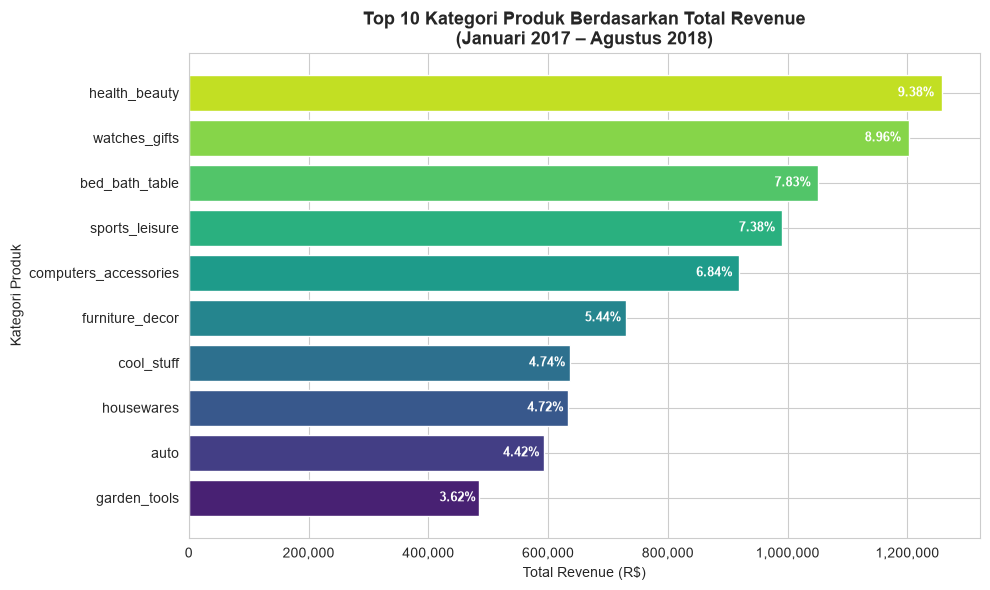

In [39]:
top10_cat = category_revenue_df.head(10).sort_values('total_revenue')

plt.figure(figsize=(10, 6))
bars = plt.barh(
    top10_cat['product_category_name_english'],
    top10_cat['total_revenue'],
    color=sns.color_palette('viridis', len(top10_cat))
)

for bar, pct in zip(bars, top10_cat['revenue_pct']):
    plt.text(
        bar.get_width() * 0.99,
        bar.get_y() + bar.get_height() / 2,
        f' {pct:.2f}%',
        va='center', ha='right', color='white', fontsize=9, fontweight='bold'
    )

plt.title('Top 10 Kategori Produk Berdasarkan Total Revenue\n(Januari 2017 – Agustus 2018)',
          fontsize=13, fontweight='bold')
plt.xlabel('Total Revenue (R$)')
plt.ylabel('Kategori Produk')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

### 6.2 Visualisasi Pertanyaan 2 — Rata-rata Waktu Pengiriman per Negara Bagian

Grafik berikut menampilkan rata-rata waktu pengiriman (dalam hari) untuk seluruh
27 negara bagian, diurutkan dari yang terlama ke tercepat. Garis putus-putus
menandai rata-rata nasional sebagai pembanding.

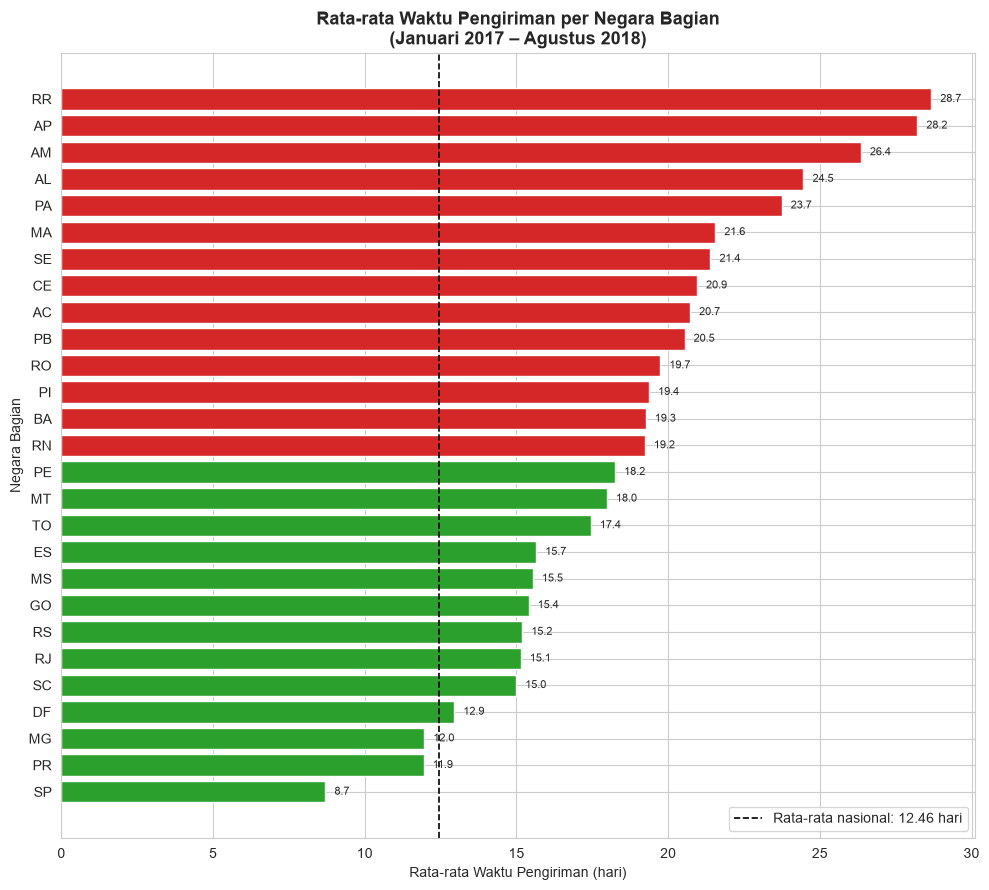

In [40]:
state_sorted = state_delivery_df.sort_values('avg_delivery_days', ascending=True)

plt.figure(figsize=(10, 9))
colors = ['#d62728' if v > state_delivery_df['avg_delivery_days'].mean() else '#2ca02c'
          for v in state_sorted['avg_delivery_days']]
bars = plt.barh(state_sorted['customer_state'], state_sorted['avg_delivery_days'], color=colors)

for bar, val in zip(bars, state_sorted['avg_delivery_days']):
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f'{val:.1f}',
        va='center', fontsize=8
    )

national_avg = delivered_df['delivery_days'].mean()
plt.axvline(national_avg, color='black', linestyle='--', linewidth=1.2,
            label=f'Rata-rata nasional: {national_avg:.2f} hari')

plt.title('Rata-rata Waktu Pengiriman per Negara Bagian\n(Januari 2017 – Agustus 2018)',
          fontsize=13, fontweight='bold')
plt.xlabel('Rata-rata Waktu Pengiriman (hari)')
plt.ylabel('Negara Bagian')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 6.3 Visualisasi Pertanyaan 3 — Segmentasi Pelanggan dengan RFM

Dua grafik berikut menampilkan distribusi pelanggan per segmen RFM:
(a) jumlah pelanggan per segmen, dan (b) kontribusi revenue per segmen.
Kombinasi keduanya memperlihatkan segmen mana yang besar secara jumlah namun
kecil kontribusinya, dan sebaliknya.

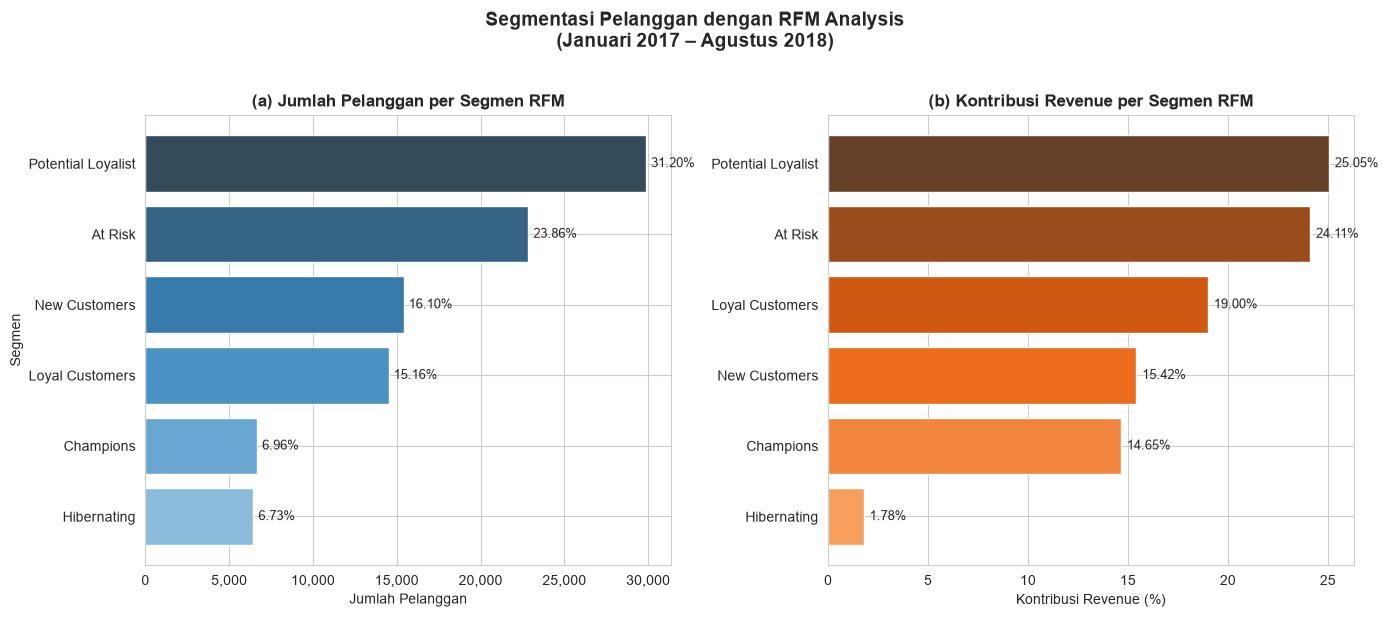

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

seg_sorted_cust = segment_summary.sort_values('customers', ascending=True)
seg_sorted_rev = segment_summary.sort_values('monetary_pct', ascending=True)

# (a) Jumlah pelanggan
bars1 = axes[0].barh(seg_sorted_cust['segment'], seg_sorted_cust['customers'],
                     color=sns.color_palette('Blues_d', len(seg_sorted_cust)))
for bar, pct in zip(bars1, seg_sorted_cust['customer_pct']):
    axes[0].text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2,
                 f'{pct:.2f}%', va='center', fontsize=9)
axes[0].set_title('(a) Jumlah Pelanggan per Segmen RFM', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jumlah Pelanggan')
axes[0].set_ylabel('Segmen')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# (b) Kontribusi revenue
bars2 = axes[1].barh(seg_sorted_rev['segment'], seg_sorted_rev['monetary_pct'],
                     color=sns.color_palette('Oranges_d', len(seg_sorted_rev)))
for bar, pct in zip(bars2, seg_sorted_rev['monetary_pct']):
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{pct:.2f}%', va='center', fontsize=9)
axes[1].set_title('(b) Kontribusi Revenue per Segmen RFM', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kontribusi Revenue (%)')
axes[1].set_ylabel('')

plt.suptitle('Segmentasi Pelanggan dengan RFM Analysis\n(Januari 2017 – Agustus 2018)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 6.4 Visualisasi Tambahan — Hubungan Frequency dan Monetary

Scatter plot berikut memperlihatkan hubungan antara frekuensi transaksi dan total
pengeluaran pelanggan. Titik diwarnai berdasarkan segmen RFM untuk melihat pola
antar segmen.

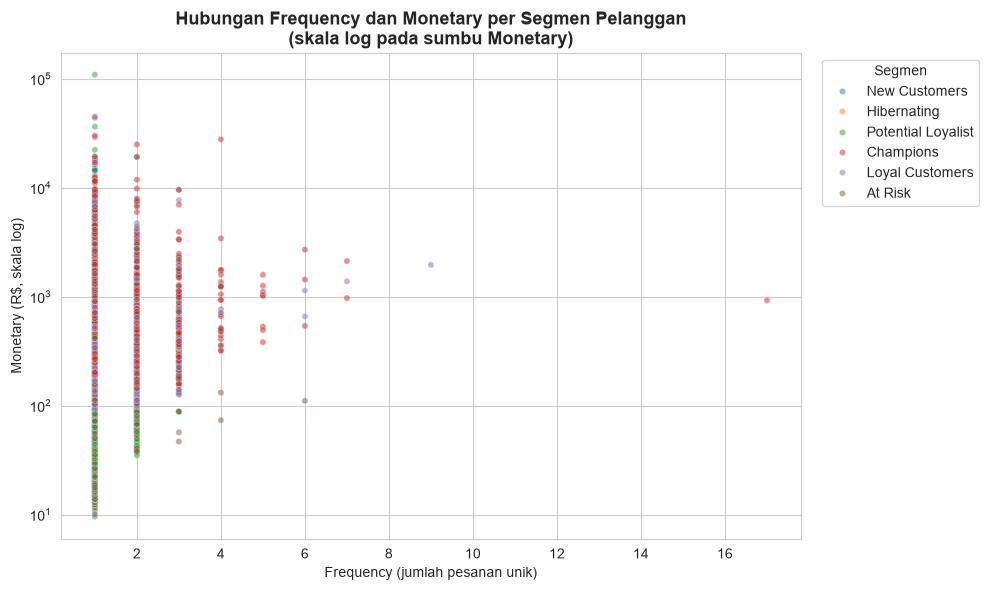

In [42]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm_df,
    x='frequency', y='monetary',
    hue='segment', palette='tab10',
    alpha=0.5, s=20
)
plt.yscale('log')
plt.title('Hubungan Frequency dan Monetary per Segmen Pelanggan\n(skala log pada sumbu Monetary)',
          fontsize=13, fontweight='bold')
plt.xlabel('Frequency (jumlah pesanan unik)')
plt.ylabel('Monetary (R$, skala log)')
plt.legend(title='Segmen', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Ringkasan Explanatory Analysis

Ketiga visualisasi di atas menjawab pertanyaan bisnis sebagai berikut:

1. **Pertanyaan 1 — Kategori Produk:** `health_beauty`, `watches_gifts`, dan
   `bed_bath_table` adalah tiga kategori penyumbang revenue terbesar (total 26,17%),
   sementara hanya 16 dari 71 kategori menyumbang ~80% revenue. Visualisasi batang
   memperlihatkan ketimpangan kontribusi ini secara langsung.

2. **Pertanyaan 2 — Waktu Pengiriman:** Terdapat disparitas besar antar negara bagian.
   RR, AP, dan AM memiliki rata-rata pengiriman > 26 hari, jauh di atas rata-rata
   nasional 12,46 hari. SP mendominasi volume (41,99%) dengan pengiriman tercepat
   (8,70 hari), sedangkan RJ memiliki volume besar (12,80%) namun pengiriman
   relatif lambat (15,14 hari) — menjadi prioritas perbaikan.

3. **Pertanyaan 3 — Segmentasi RFM:** Potential Loyalist (31,20% pelanggan, 25,05%
   revenue) dan At Risk (23,86% pelanggan, 24,11% revenue) adalah dua segmen terbesar.
   Champions hanya 6,96% pelanggan tetapi memiliki rata-rata monetary tertinggi
   (Rp 450,42) dan menyumbang 14,65% revenue — aset utama untuk program loyalitas.

## 7. Conclusion & Recommendation

Pada tahap ini, ditarik kesimpulan dari hasil EDA dan visualisasi yang telah dilakukan,
serta dirumuskan rekomendasi action item yang dapat ditindaklanjuti oleh stakeholder.

### 7.1 Conclusion

**Kesimpulan Pertanyaan 1 — Kategori Produk:**

Selama periode Januari 2017 – Agustus 2018, total revenue mencapai **Rp 13.416.140,03**
dari 71 kategori produk. Revenue sangat terkonsentrasi: hanya **16 dari 71 kategori
(22,5%)** yang menyumbang sekitar **79,08%** total revenue. Tiga kategori teratas —
**health_beauty** (9,38%), **watches_gifts** (8,96%), dan **bed_bath_table** (7,83%) —
menyumbang 26,17% revenue. Sebaliknya, kategori **security_and_services**,
**fashion_childrens_clothes**, dan **cds_dvds_musicals** memiliki kontribusi
di bawah 0,01%, menandakan permintaan yang sangat rendah.

**Kesimpulan Pertanyaan 2 — Waktu Pengiriman:**

Dari 110.511 pesanan berstatus `delivered`, rata-rata waktu pengiriman nasional adalah
**12,46 hari** (median 10,18 hari). Terdapat disparitas geografis yang signifikan:
state **RR (28,67 hari)**, **AP (28,21 hari)**, dan **AM (26,35 hari)** memiliki waktu
pengiriman terlama — lebih dari dua kali rata-rata nasional. Sebaliknya **SP (8,70 hari)**
memiliki pengiriman tercepat sekaligus mendominasi volume pesanan (41,99%). **RJ**
menjadi perhatian khusus: volume pesanan besar (12,80%) tetapi waktu pengiriman
relatif lambat (15,14 hari).

**Kesimpulan Pertanyaan 3 — Segmentasi RFM:**

Dari **95.773 pelanggan unik**, mayoritas hanya bertransaksi satu kali (median
frequency = 1), menandakan rendahnya repeat purchase. Segmen **Potential Loyalist**
(31,20% pelanggan, 25,05% revenue) dan **At Risk** (23,86% pelanggan, 24,11% revenue)
adalah dua segmen terbesar. **Champions** hanya 6,96% pelanggan tetapi memiliki
rata-rata monetary tertinggi (Rp 450,42) dan menyumbang 14,65% revenue. Segmen
**Hibernating** (6,73% pelanggan) hanya menyumbang 1,78% revenue — pelanggan bernilai
rendah yang memerlukan pendekatan berbiaya rendah.

### 7.2 Recommendation

Berdasarkan kesimpulan di atas, berikut rekomendasi action item yang dapat
ditindaklanjuti:

**Action Item 1 — Optimalisasi Kategori Produk Prioritas**

Fokuskan alokasi stok, anggaran promosi, dan kemitraan penjual pada 16 kategori
penyumbang ~80% revenue (terutama `health_beauty`, `watches_gifts`, `bed_bath_table`).
Untuk kategori berkinerja rendah (`security_and_services`, `fashion_childrens_clothes`,
`cds_dvds_musicals`), lakukan evaluasi: kurangi stok atau hentikan kemitraan jika
tidak menunjukkan pertumbuhan dalam 2 kuartal ke depan.
*Metrik keberhasilan:* peningkatan revenue share 16 kategori utama dari 79,08%
menjadi ≥ 82% dalam 2 kuartal.

**Action Item 2 — Perbaikan Logistik di Wilayah Prioritas**

Prioritaskan perbaikan logistik di **RJ** (volume besar + pengiriman lambat) dan
wilayah **Utara (RR, AP, AM, PA)** dengan menambah mitra kurir lokal atau
membangun gudang transit regional. Targetkan penurunan rata-rata waktu pengiriman
di state tersebut sebesar 20% dalam 6 bulan.
*Metrik keberhasilan:* rata-rata delivery_days RJ turun dari 15,14 menjadi ≤ 12 hari;
rata-rata nasional turun dari 12,46 menjadi ≤ 11 hari.

**Action Item 3 — Program Retensi dan Reaktivasi Berbasis RFM**

- **Champions (6.667 pelanggan):** berikan program loyalitas eksklusif (early access,
  cashback, dedicated support) untuk mempertahankan kontribusi revenue 14,65%.
- **At Risk (22.849 pelanggan):** jalankan kampanye reaktivasi (email/push notification
  dengan diskon terbatas) karena segmen ini menyumbang 24,11% revenue namun sudah
  lama tidak bertransaksi (rata-rata recency 395 hari).
- **Potential Loyalist (29.878 pelanggan):** dorong pembelian kedua melalui
  voucher "second purchase" dalam 30 hari setelah transaksi pertama.
- **Hibernating (6.445 pelanggan):** gunakan kampanye berbiaya rendah (email blast,
  bukan diskon besar) karena kontribusi revenue hanya 1,78%.
*Metrik keberhasilan:* peningkatan repeat purchase rate dari 1,03 menjadi ≥ 1,15
dalam 2 kuartal; penurunan jumlah pelanggan At Risk sebesar 15%.

---

**Catatan metodologi:**
Analisis ini menggunakan data transaksi e-commerce publik periode Januari 2017 –
Agustus 2018. Seluruh pengolahan dilakukan dengan Python (pandas, matplotlib, seaborn)
tanpa algoritma machine learning. Segmentasi RFM menggunakan pendekatan kuantil dan
aturan bisnis (manual grouping) sesuai panduan proyek. Hasil analisis telah
divisualisasikan dan didokumentasikan untuk mendukung pengambilan keputusan.